# Investigação adicional de autorregressão

São 177 candidatos. A escolha usa somente anos anteriores a 1947. A comparação de 1947–2008 já era conhecida. O candidato reduz MAPE, mas não supera o AR9 em MAE e RMSE; o padrão foi preservado. Todas as entradas são observações reais anteriores.


In [1]:
from pathlib import Path
from IPython.display import display, Image, Markdown
from manchas_avaliacao_avancada import executar, exportar, relatorio, graficos
pasta=Path.cwd()
e=executar(pasta,progresso=True)
display(e['busca'].head(12).drop(columns='config').round(3))
display(e['blocos'].round(3))


Busca de desenvolvimento carregada do cache verificado.


,id,familia,p,transformacao,alvo,alpha,janela,meia_vida,MAE_cv,RMSE_cv,MAE_fold_1,MAE_fold_2,MAE_fold_3,MAE_fold_4
0,121,kernel_rbf,5,raiz,nivel,0.1,0,0,8.447,11.397,7.446,10.125,7.701,8.517
1,127,svr,5,raiz,nivel,1.0,0,0,8.521,11.674,8.388,9.343,7.293,9.078
2,129,svr,5,raiz,nivel,1.0,0,0,8.611,11.748,8.044,10.109,7.570,8.725
3,140,spline,9,raiz,nivel,1.0,0,0,8.856,11.995,8.087,11.014,7.619,8.700
4,47,svr,5,original,nivel,1.0,0,0,8.917,12.032,8.132,10.343,7.915,9.290
5,92,spline,3,raiz,nivel,1.0,0,0,8.941,12.031,9.880,9.098,7.934,8.848
6,104,svr,3,raiz,nivel,1.0,0,0,9.002,12.393,8.712,10.066,8.903,8.307
7,97,kernel_rbf,3,raiz,nivel,0.1,0,0,9.030,11.913,9.453,9.661,8.240,8.757
8,98,kernel_rbf,3,raiz,nivel,0.1,0,0,9.060,12.441,9.013,10.563,8.917,7.705
9,105,svr,3,raiz,nivel,1.0,0,0,9.078,12.369,9.002,9.879,8.185,9.253


,bloco,inicio,fim,tipo,ids,MAE,MAE_AR9,variacao
0,2,1852,1883,individual,[121],10.125,11.250,-0.100
1,3,1884,1915,media_tres_familias,"[121, 127, 92]",7.498,6.912,0.085
2,4,1916,1946,media_tres_familias,"[127, 121, 140]",8.584,10.136,-0.153


,Modelo,MAE,RMSE,R2,MAPE,WAPE,MASE,Vies
0,AR9 padrão preservado,13.284,16.990,0.896,34.138,18.011,0.811,-2.970
1,Candidato experimental,14.364,19.696,0.861,31.444,19.474,0.877,-7.874
2,AR19 original,15.278,20.241,0.853,36.267,20.715,0.933,-5.883
3,Persistência,25.444,33.276,0.603,55.417,34.497,1.554,1.447


,Modelo,Faixa,Anos,MAE,RMSE,R2,MAPE,WAPE,MASE,Vies
0,AR9,Até 10,4,7.504,8.093,-11.423,1.702,1.283,0.458,7.504
1,Experimental,Até 10,4,6.476,6.811,-7.798,1.471,1.107,0.396,6.476
2,AR9,10 a 50,23,8.882,10.762,0.065,0.378,0.335,0.542,-1.909
3,Experimental,10 a 50,23,8.034,10.368,0.132,0.328,0.303,0.491,-1.613
4,AR9,50 a 100,13,15.858,19.065,-0.716,0.208,0.213,0.968,0.295
5,Experimental,50 a 100,13,13.289,17.185,-0.395,0.182,0.179,0.812,-0.211
6,AR9,Acima de 100,22,17.417,21.580,0.291,0.134,0.129,1.064,-7.914
7,Experimental,Acima de 100,22,23.050,28.248,-0.215,0.168,0.171,1.408,-21.557


,Ganho médio MAE,"Limite 2,5%","Limite 97,5%",Comprimento bloco,Reamostragens
0,-1.079,-5.781,1.778,11,5000


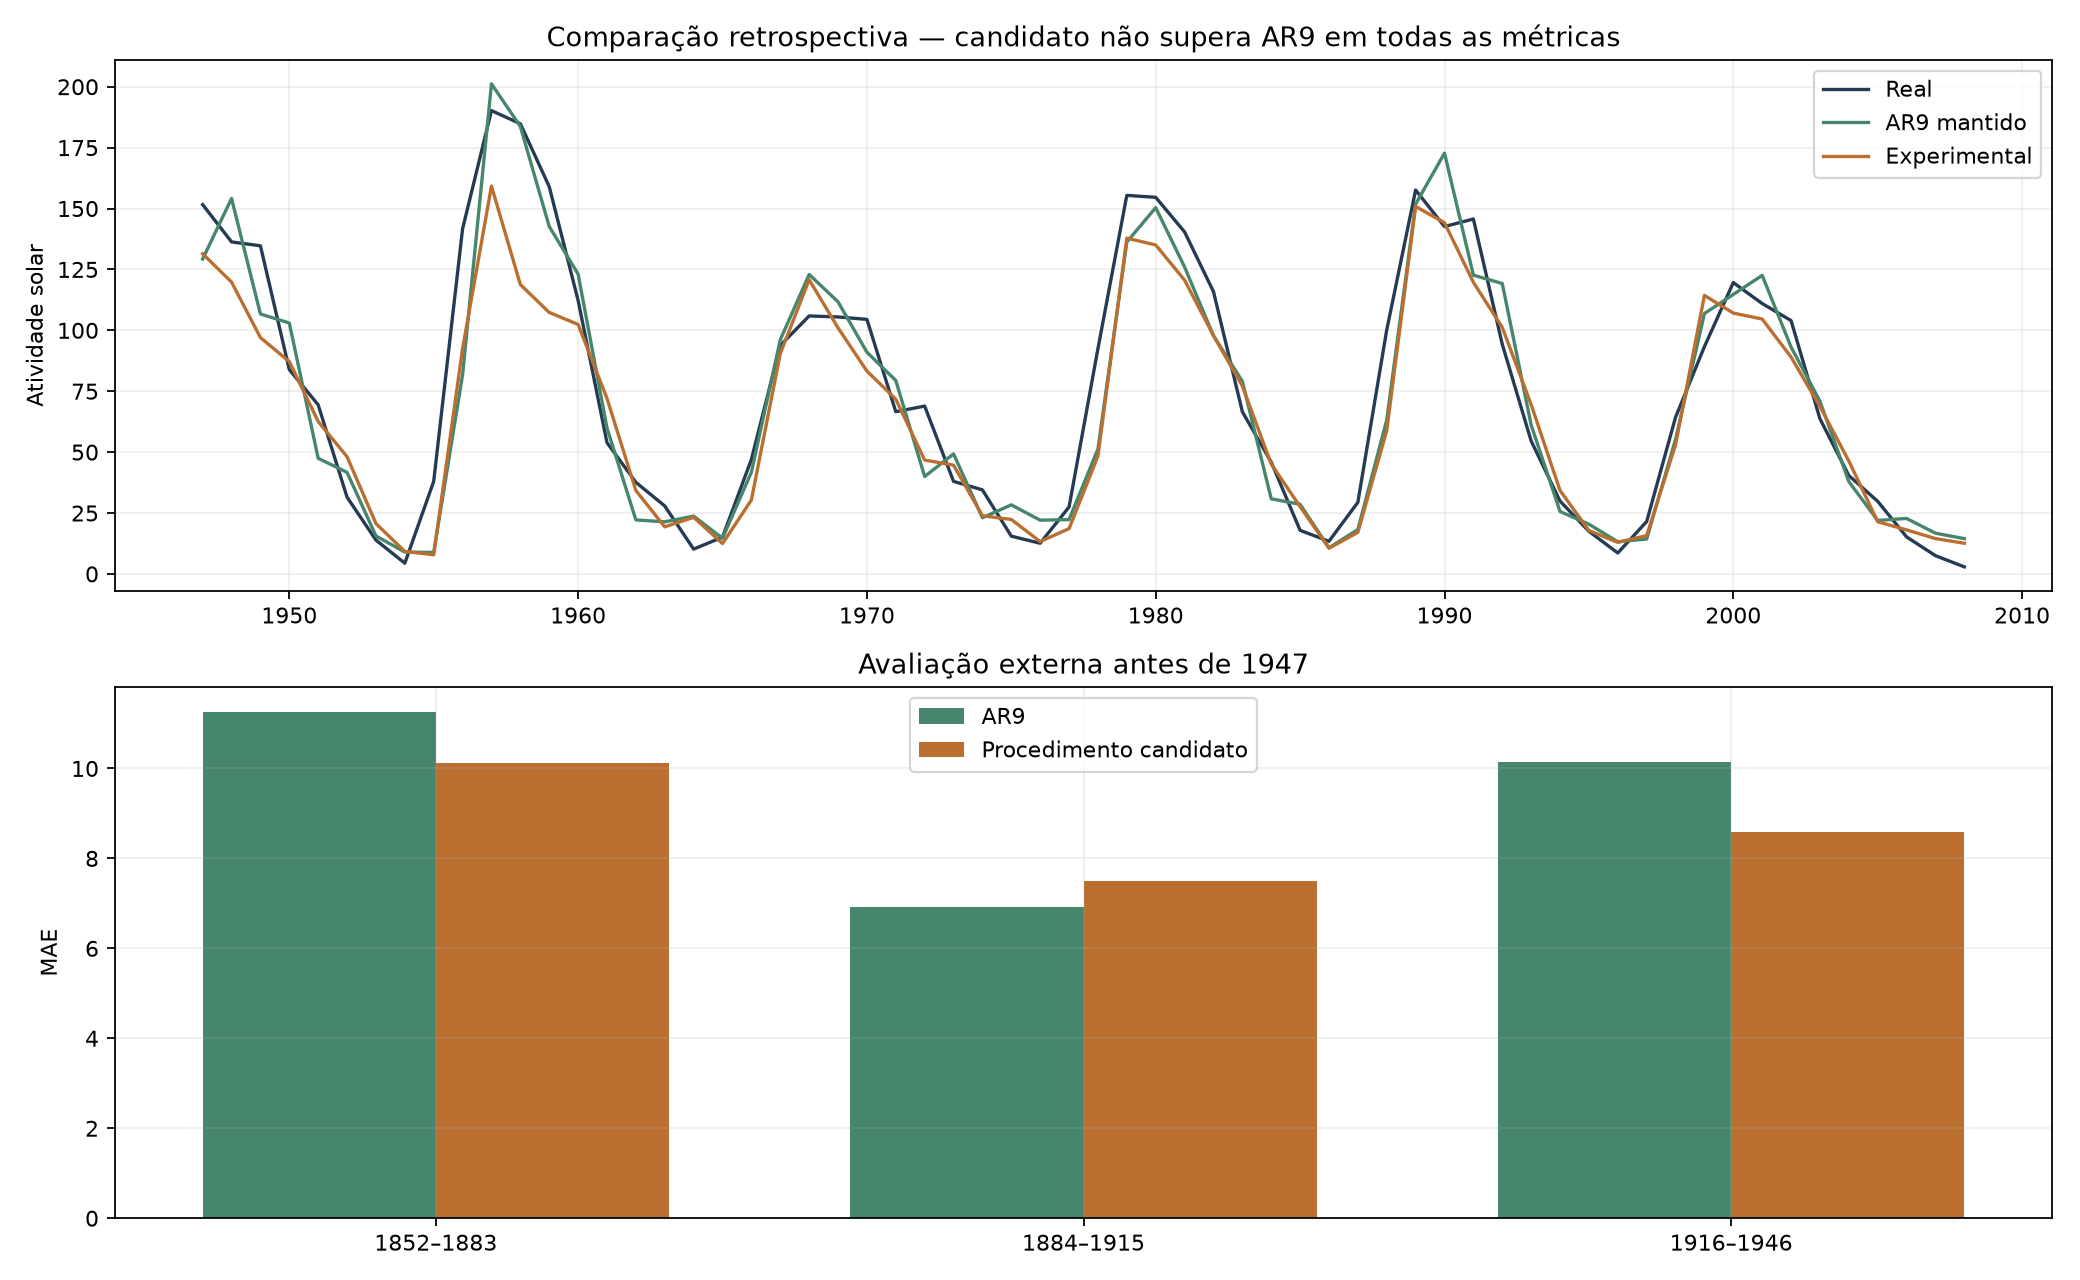

# Investigação avançada de autorregressão

## Conclusão

O AR9 continua como padrão. A busca adicional encontrou um candidato melhor na validação e no erro percentual retrospectivo, mas ele piorou MAE e RMSE na comparação histórica. Não há evidência para prometer um modelo globalmente melhor nem um máximo atingido.

## O que foi testado

177 configurações adicionais, sem variáveis externas: AR com histórico recente/pesos por recência, seleção esparsa de defasagens, diferenças, interações quadráticas, splines, Kernel Ridge RBF, SVR, modelos por regime de subida/queda ou nível, ElasticNet e gradient boosting.
O horizonte continua sendo um ano à frente. Cada ajuste recebe apenas o histórico real anterior ao alvo. A transformação, a padronização, os regimes e as janelas são calculados apenas nesse histórico. Nenhuma previsão é reinserida como entrada.

## Seleção antes de consultar 1947–2008 nesta rodada

Quatro blocos: 1820–1851, 1852–1883, 1884–1915 e 1916–1946. Comparamos o melhor modelo individual com a média dos três melhores de famílias diferentes. O critério é MAE, não MAPE.
Na avaliação externa, cada bloco escolhe seus modelos exclusivamente pelos blocos anteriores. A regra registrada antes da comparação exige pelo menos 2% menos MAE externo que AR9, sem piora maior que 20% em nenhum bloco.
A regra foi satisfeita: MAE externo 8.737, contra 9.425 do AR9. O candidato final é uma média simples dos modelos [121, 127, 140].

Componentes escolhidos:
- {"familia": "kernel_rbf", "lags": [1, 2, 3, 4, 5], "transformacao": "raiz", "alpha": 0.1, "janela": 0, "meia_vida": 0, "alvo": "nivel", "gamma": 0.1}
- {"familia": "svr", "lags": [1, 2, 3, 4, 5], "transformacao": "raiz", "alpha": 1.0, "janela": 0, "meia_vida": 0, "alvo": "nivel", "C": 1, "gamma": 0.1}
- {"familia": "spline", "lags": [1, 2, 3, 4, 5, 6, 7, 8, 9], "transformacao": "raiz", "alpha": 1, "janela": 0, "meia_vida": 0, "alvo": "nivel"}

Melhor configuração de cada família na própria busca (medida otimista):

| Família | MAE CV |
| --- | ---: |
| kernel_rbf | 8.447 |
| svr | 8.521 |
| spline | 8.856 |
| quadratico | 9.315 |
| regime_fase | 9.326 |
| boosting | 9.613 |
| regime_nivel | 9.631 |
| ridge | 9.745 |
| elasticnet | 9.808 |

## Comparação retrospectiva de 1947–2008

| Modelo | MAE | RMSE | R² | MAPE |
| --- | ---: | ---: | ---: | ---: |
| AR9 padrão preservado | 13.28 | 16.99 | 0.896 | 34.14% |
| Candidato experimental | 14.36 | 19.70 | 0.861 | 31.44% |
| AR19 original | 15.28 | 20.24 | 0.853 | 36.27% |
| Persistência | 25.44 | 33.28 | 0.603 | 55.42% |

O candidato apresentou MAE 8.1% maior e RMSE 15.9% maior. O MAPE caiu de 34.14% para 31.44%. Isso é uma troca entre métricas, não uma melhora geral.
Ganho de MAE (positivo favorece o candidato), bootstrap descritivo por blocos de 11 anos: -1.079; intervalo percentil de 95% [-5.781, 1.778]. A análise não corrige pelo amplo processo de seleção e usa poucos ciclos.
A explicação é compatível com limitação de extrapolação de modelos não lineares e mudanças na amplitude dos ciclos; os erros por faixa e os componentes individuais estão no Excel. Essa interpretação é uma hipótese diagnóstica, não uma causa demonstrada.

## Limites da investigação

O período de 1947–2008 já era conhecido. A nova busca não recebe esses alvos, mas foi motivada por resultados anteriores: a comparação é retrospectiva. Não houve nova rodada de ajuste depois de abrir seus resultados nesta etapa.
A regra externa também é um critério de seleção do procedimento; seus números não substituem um teste novo. O ganho no desenvolvimento não se transferiu integralmente para o período histórico posterior.
Continuar aumentando a busca no mesmo conjunto pode melhorar números por acaso. Não adotamos um componente isolado só porque ele eventualmente teria um resultado melhor nesse período já visto.
Consultamos a série anual atualizada SILSO v2, mas não foi possível obter o arquivo completo nesta sessão. Nenhum número foi preenchido manualmente, e versões diferentes do índice não foram concatenadas. Sem esse arquivo verificado, a avaliação em anos novos ficou pendente.

## Executar

```bash
uv run --locked python prever_manchas.py --avancado
# Refazer todos os 177 candidatos:
uv run --locked python prever_manchas.py --avancado --refazer-busca
```

O comando padrão sem --avancado mantém o AR9 e a investigação anterior. A busca usa um cache com hash do código e do CSV para garantir correspondência. O Excel avançado exibe os dois resultados lado a lado, sem trocar silenciosamente o modelo padrão.

## Fontes técnicas

- https://scikit-learn.org/stable/modules/generated/sklearn.kernel_ridge.KernelRidge.html
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html
- https://www.sidc.be/SILSO/infosnytot


Excel: /Users/ryanbernardo/Documents/Faculdade/MachineLearning/projeto_auto_regressao/resultados_manchas_solares/investigacao_avancada_manchas.xlsx


In [2]:
m=e['comparacao'].copy()
m[['MAPE','WAPE']]*=100
display(m.round(3))
display(e['faixas'].round(3))
display(e['bootstrap'].round(3))
saida=exportar(e,pasta)
texto=relatorio(e,pasta)
graficos(e,pasta)
display(Image(filename=str(saida.parent/'comparacao_avancada.png')))
display(Markdown(texto.read_text()))
print('Excel:',saida)
